In [1]:
# Returns the binary representation of n; if t>0, padded with zeroes so that its length is not less than t.
def binary(n, t = -1):
    if t > 0:
        return '{0:b}'.format(n).rjust(t, '0')
    return '{0:b}'.format(n)

# Finds the 2-fatness of x, i.e., the largest k such that 2^k divides x (float('inf') if x is zero)
def fatness(x):
    if x == 0:
        return float('inf')
    k = 0
    while x % 2 == 0:
        k += 1
        x //= 2
    return k

# Finds the 2-fattest number in the interval [x..y]
def fattest(x, y):
    ftst = 0
    maxf = -1
    for k in range(x, y + 1):
        f = fatness(k)
        if f > maxf:
            maxf = f
            ftst = k
    return ftst

# Finds the 2-fat jump of x, i.e., the smallest value larger than x with larger fatness than x
def _fat_jump(x):
    f = fatness(x)
    y = x + 1
    while not fatness(y) > f:
        y += 1
    return y

# Finds the n-th iterated 2-fat jumpt of x, i.e., applies _fatJump n times to x. If x = 0, it returns None
def fat_jump(x, n = 1):
    if x == 0:
        return None
    for k in range(n):
        x = _fat_jump(x)
    return x

# Finds the 2-fat backjump of x, i.e., the largest value smaller than x with larger fatness than x. If x = 0, it returns None
def _fat_backjump(x):
    f = fatness(x)
    y = x - 1
    while not fatness(y) > f:
        y -= 1
    return y

# Finds the n-th iterated 2-fat bacljumpt of x, i.e., applies _fatBackJump n times to x. If x = 0, it returns None
def fat_backjump(x, n = 1):
    if x == 0:
        return 0
    for k in range(n):
        if x == 0:
            return 0
        x = _fat_backjump(x)
    return x

# Returns the set of all backjumps of x
def all_fat_backjumps(x):
    s = set()
    while x>0:
        s.add(x)
        x=fat_backjump(x)
    s.add(x)
    return s

In [2]:
!pip install graphviz
from graphviz import Graph
from IPython.display import Image

In [31]:
# Definition for a binary tree node.
class TrieNode(object):
    def __init__(self, name, content, trie):
        self.name = name       # Node name
        self.content = content # Node content
        self.extent = name + content 
                               # Node extent
        self.left = None       # Reference to left (0) child
        self.right = None      # Reference to right (1) child
        self.i = len(name) - 1 # Left extreme of the skip interval (exclusive) [length of name - 1]
        self.j = len(self.extent) 
                               # Right extreme of the skip interval (inclusive) [length of extent]
        self.handle_length = fattest(self.i + 1, self.j)
                               # Length of the handle
        self.handle = self.extent[:self.handle_length]
                               # Actual handle
        self.hoff = self.handle_length - len(self.name)
                              # The number of characters of the content that are part of the handle
        self.symbolic_name = trie.get_name()
        self.next = None      # Reference to the next leaf (valid only if this is a leaf)
        self.prev = None      # Reference to the previous leaf
            
            
    def __str__(self):
        return self.symbolic_name
    
    def is_leaf(self):
        return self.left is None
    
    # Returns the set of ancestors of the node
    def find_ancestors(self, node):
        s = set([])
        if node.name.startswith(self.name):
            s.add(self)
        if self.left:
            s |= self.left.find_ancestors(node)
        if self.right:
            s |= self.right.find_ancestors(node)
        return s

    
# Formats the content (s) of the node, and separates the upper and lower half (t characters before the lower half)
def format_name(s, t):
    res ='<<table port="port" border="0" cellborder="0" cellspacing="0" cellpadding="2">'
    if s == "":
        res += '<tr><td height="4" width="10" fixedsize="true"></td></tr><hr/>'
        res += '<tr><td height="4" width="10" fixedsize="true"></td></tr>'
    else:
        if t == 0:
            res += '<tr><td height="1"></td></tr>'
        for i in range(len(s)):
            if i == t:
                res += '<hr/>'
            res += '<tr><td>' + s[i] + '</td></tr>'
        if t == len(s):
            res += '<tr><td height="1"></td></tr><hr/>'
            res += '<tr><td height="1"></td></tr>'
    res += '</table>>'
    return res
        
# Returns the dot version of the given tree. Given dot=visualize_tree(t), just do dot to visualize it
# dot.save('xxx.dot') to save it with filename 'xxx.dot'.
def to_dot(trie):
    def add_nodes_edges(tree, dot=None):
        # Create Digraph object
        if dot is None:
            dot = Graph()
            dot.attr('node', shape='box')
            dot.attr('node', width='0.01')
            dot.attr('node', margin='0')
            dot.attr('graph', labelfloat='true')
            dot.attr(splines='true')
            dot.node(name=str(tree), label=format_name(tree.content, tree.hoff))

        # Add nodes
        if tree.left:
            dot.node(name=str(tree.left), label=format_name(tree.left.content, tree.left.hoff))
            dot.edge(str(tree), str(tree.left), label='0')#, headport='n', tailport='s') 
            dot = add_nodes_edges(tree.left, dot=dot)
            
        if tree.right:
            dot.node(name=str(tree.right) ,label=format_name(tree.right.content, tree.right.hoff))
            dot.edge(str(tree), str(tree.right), label='1')#, headport='n', tailport='s')
            dot = add_nodes_edges(tree.right, dot=dot)

        return dot
    
    # Add nodes recursively and create a list of edges
    dot = add_nodes_edges(trie.root)

    return dot

In [116]:
# Returns the lcp of a set of strings
def lcp(strs):
    longest_pre = ''
    if not strs: return longest_pre
    shortest_str = min(strs, key=len)
    for i in range(len(shortest_str)):
        if all([x.startswith(shortest_str[:i+1]) for x in strs]):
            longest_pre = shortest_str[:i+1]
        else:
            break
    return longest_pre

# Returns the root of the compacted trie for the list of strings strs
def trie(strs, host_trie, name=""):
    pref = lcp(strs)
    lenP = len(pref)
    t = TrieNode(name, pref, host_trie)
    if len(strs) == 1:
        t.prev = host_trie.last_leaf
        t.next = None
        if host_trie.last_leaf is None:
            host_trie.last_leaf = t
            host_trie.first_leaf = t
        else:
            host_trie.last_leaf.next = t
            host_trie.last_leaf = t
        return t
    strs0 = [x[lenP+1:] for x in strs if x[lenP] == '0']
    strs1 = [x[lenP+1:] for x in strs if x[lenP] == '1']
    t.left = trie(strs0, host_trie, name=name + pref + '0')
    t.right = trie(strs1, host_trie, name=name + pref + '1')
    return t

In [117]:
class Trie(object):
    def __init__(self, s):
        self.number_of_nodes = 0
        self.first_leaf = None
        self.last_leaf = None
        self.z = {}
        self.root = trie(s, self)
        self.build_z(self.root)
        
    def build_z(self, node):
        if node and node.left and node.right:
            self.z[node.handle] = node
            self.build_z(node.left)            
            self.build_z(node.right)
     
    # Returns the set of all  ancestors of the node (including the node itself)
    def find_ancestors(self, node):
        return self.root.find_ancestors(node)
    
    # Returns the set of all 2-fat ancestors of the node
    def find_fat_ancestors(self, node):
        ancestors = self.find_ancestors(node)
        bj = all_fat_backjumps(len(node.handle))
        return set([ancestor for ancestor in ancestors if len(ancestor.handle) in bj])
    
    # Returns the left descendant leaf of the given node
    def left_dleaf(self, node):
        while node.left:
            node = node.left
        return node
    
    # Returns the right descendant leaf of the given node
    def right_dleaf(self, node):
        while node.right:
            node = node.right
        return node
    
    
    # Algorithm 1: given a string x, returns a stack containing on the top exit(x) or parex(x), and
    # below it its fat ancestors.
    # The starting search interval is set to [a..b]. Use b=-1 for b=len(x). The default is [0..len(x)].
    def locate_exit_or_parex(self, x, verbose=False, a=0, b=-1, startingStack=[]):
        s = startingStack.copy()
        if verbose:
            print("Starting stack: {}".format([x.name for x in s]))
        if b < 0:
            b = len(x)
        count = 0
        if verbose:
            print("Interval [{}..{}]".format(a,b))
        while a <= b:
            count += 1
            f = fattest(a, b)
            if verbose:
                print("f={}, query with '{}'".format(f, x[:f]))
            query = x[:f]
            if query in self.z:
                beta = self.z[query]
                if verbose:
                    print("Result: node named {}".format(beta.name))
                a = len(beta.extent) + 1
                s.append(beta)
            else:
                if verbose:
                    print("Result: -")
                b = f - 1
            if verbose:
                print("Interval [{}..{}]".format(a,b))
        return s, count

    # Algorithm 1: given a string x, returns a stack containing on top parex(x), and
    # below it its fat ancestors.
    # The starting search interval is set to [a..b]. Use b=-1 for b=len(x). The default is [0..len(x)].
    def locate_parex(self, x, verbose=False, a=0, b=-1, startingStack=[]):
        s = startingStack.copy()
        if verbose:
            print("Starting stack: {}".format([x.name for x in s]))
        if b < 0:
            b = len(x)
        count = 0
        if verbose:
            print("Interval [{}..{}]".format(a,b))
        while a <= b:
            count += 1
            f = fattest(a, b)
            if verbose:
                print("f={}, query with '{}'".format(f, x[:f]))
            query = x[:f]
            if query in self.z and x.startswith(self.z[query].extent) and x != self.z[query].extent:
                beta = self.z[query]
                if verbose:
                    print("Result: node named {}".format(beta.name))
                a = len(beta.extent) + 1
                s.append(beta)
            else:
                if verbose:
                    if not query in self.z:
                        print("Result: -")
                    else:
                        print("Result: node named {}, but discarded".format(self.z[query].name))
                b = f - 1
            if verbose:
                print("Interval [{}..{}]".format(a,b))
        return s, count
    
    # Adapting locate_exit_or_parex to return the exit or parex node (depending on needsExit).
    # Note that search(self, x)=locate_parex(self, x) should be true for all x.
    def search(self, x, verbose=False, needsExit=False):
        if verbose:
            print("Starting search")
        s, c = self.locate_exit_or_parex(x, verbose, startingStack=[])
        if verbose:
            print("Returned stack {}".format([x.name for x in s]))
        if len(s) == 0:   # Returned an empty stack: exiting at the root
            if verbose:
                print("Got an empty stack: exit node is the root")
            if needsExit:
                return self.root, c
            else:
                return None, c
        t = s[-1] # Exit or parexit
        if x.startswith(t.extent) and x != t.extent:   # t is parex 
            if verbose:
                print("Parex on top")
            if not needsExit:
                return s[-1], c
            if verbose:
                print("Got parex, but needs exit: check bit number {}".format(len(t.extent)))
            if x[len(t.extent)] == '0':
                return t.left, c
            else:
                return t.right, c
        else:                                          # t exit
            lenParexExtent = len(t.name) - 1
            if needsExit:
                return s[-1], c
            if verbose:
                print("Needed parex but got exit; popping the exit node")
            t = s[-1]
            s.pop()
            if t == self.root: # Exit node was the root
                if needsExit:
                    return self.root, c
                else:
                    return None, c
            if len(s) == 0:
                if verbose:
                    print("Restaring the search from ({},{}] and s={}".format(0, lenParexExtent, s))
                new_s, c1 = self.locate_exit_or_parex(x, verbose, a=0, b=lenParexExtent, startingStack=s)
            else:
                if verbose:
                    print("Restaring the search from ({},{}] and s={}".format(len(s[-1].extent), lenParexExtent, s))
                new_s, c1 = self.locate_exit_or_parex(x, verbose, a=len(s[-1].extent), b=lenParexExtent, startingStack=s)
            if len(new_s) == 0:
                if verbose:
                    print("Got an empty stack: exit node is the root")
                if needsExit:
                    return self.root, c
                else:
                    return None, c
            return new_s[-1], c+c1
                    
    def get_name(self):
        x = self.number_of_nodes
        res = chr(x % 26 + ord('A'))
        x //= 26
        while x > 0:
            res += chr(x % 26 + ord('A'))
            x //= 26
        self.number_of_nodes += 1
        return res

In [412]:
####### HIGH level queries
# Let x exit at exitNode of trie t. Returns true if it exits left
def exitsLeft(t, x, exitNode):
    if (exitNode.extent.startswith(x)):
        return True
    w = lcp([x, exitNode.extent])
    if len(w) < len(x) and len(w) < len(exitNode.extent) and x[len(w)] == '0':
        return True
    return False

def predecessor(t, x, verbose=False):
    exit_node = t.search(x, verbose=verbose, needsExit=True)[0]
    if verbose:
        print("Exit node name: '{}'".format(exit_node.name))
    exits_left = exitsLeft(t, x, exit_node)
    if verbose:
        print("Exit left? {}".format(exits_left))
    if exits_left:
        return t.left_dleaf(exit_node).prev
    else:
        return t.right_dleaf(exit_node)
    
def successor(t, x, verbose=False):
    exit_node = t.search(x, verbose=verbose, needsExit=True)[0]
    if verbose:
        print("Exit node name: '{}'".format(exit_node.name))
    exits_left = exitsLeft(t, x, exit_node)
    if verbose:
        print("Exit left? {}".format(exits_left))
    if exits_left:
        return t.left_dleaf(exit_node)
    else:
        return t.right_dleaf(exit_node).next
    
def prefix(t, x, verbose=False):
    exit_node = t.search(x, verbose=verbose, needsExit=True)[0]
    if verbose:
        print("Exit node name: '{}'".format(exit_node.name))
    if exit_node.extent.startswith(x):
        left = t.left_dleaf(exit_node)
        right = t.right_dleaf(exit_node)
        curr = left
        result = [left.extent]
        while curr != right:
            curr = curr.next
            result.append(curr.extent)
        return result
    else:
        return []
    exits_left = exitsLeft(t, x, exit_node)
    if verbose:
        print("Exit left? {}".format(exits_left))
    if exits_left:
        return t.left_dleaf(exit_node)
    else:
        return t.right_dleaf(exit_node).next
    
def rangeExistential(t, x, y, verbose=False):
    exx = t.search(x, verbose=verbose, needsExit=True)[0]
    exxl = exitsLeft(t, x, exx)
    if verbose:
        print("x exits at node named '{}'; exits left? {}".format(exx.name, exxl))
    exy = t.search(y, verbose=verbose, needsExit=True)[0]
    exyl = exitsLeft(t, y, exy)
    if verbose:
        print("y exits at node named '{}'; exits left? {}".format(exy.name, exyl))
    alpha = exx
    while alpha.left is not None and len(alpha.extent) < len(y):
        print("*****", alpha.name, "->", alpha.right)
        if exxl:
            alpha = alpha.left
        else:
            alpha = alpha.right
    #if not exxl:
    #    alpha = alpha.next
    beta = exy
    while beta.right is not None and len(beta.extent) < len(x):
        if exyl:
            beta = beta.left
        else:
            beta = beta.right
    #if exyl and y == beta.extent:
    #    beta = beta.next
    if verbose:
        if alpha is None:
            alphan=None
        else:
            alphan=alpha.name
        if beta is None:
            betan=None
        else:
            betan=beta.name
        print("alpha name='{}'\nbeta name='{}'".format(alphan, betan))
    return alpha != None and (beta == None or (beta.extent>= x and alpha.extent<y))
    

In [401]:
import random
import numpy
def gen(s, k):
    if k < 4:
        return [s + ''.join([random.choice(['0', '1']) for i in range(k)])]
    if k < 6:
        k1 = random.randint(3, k)
    else:
        k1 = min(random.randint(3, max(4, k // 4)), k - 1)
    s += ''.join([random.choice(['0', '1']) for i in range(k1)])
    a = gen(s + '0', k - k1 - 1)
    a.extend(gen(s + '1', k - k1 - 1))
    return a

In [402]:
strs = gen('', 20)
strs=[
'0111010100110011',
'01110101001110100000',
'011101010011110001110',
'01110101001111101',
'01110101111110110001',
'01110101111110110111',
'0111010111111100001',
'011101011111110001',
'01111110101001011000',
'01111110101001010',
'0111111010100111000011',
'0111111010100111001110',
'01111110111001000',
'0111111011100101',
'01111110111001100001',
'01111110111001100011'
]
#strs = gen('', 40)

strs.sort()
t = Trie(strs)
dot = to_dot(t)

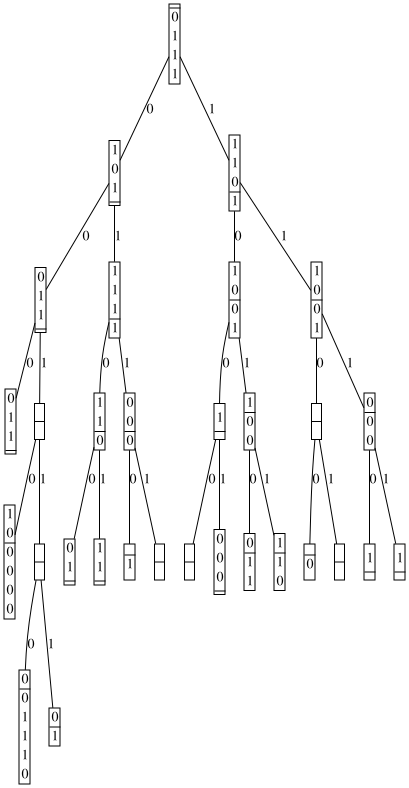

In [354]:
display(dot)

In [410]:
##CHECK rangeExistential
maxS = max([len(x) for x in strs])
for times in range(10000):
    ql = random.randint(1, maxS + 5)
    queryx = ''.join([random.choice(['0', '1']) for i in range(ql)])
    ql = random.randint(1, maxS + 5)
    queryy = ''.join([random.choice(['0', '1']) for i in range(ql)])
    if queryx > queryy:
        continue
    actual = rangeExistential(t, queryx, queryy, False)
    expected = len([x for x in strs if x >= queryx and x < queryy])>0
    print(actual, expected)
    if actual != expected:
        print("Existential range query:  \t[{},{})\nExpected: \t{}\nActual: \t{}\n".format(queryx, queryy, expected, actual))
        break

*****  -> Q
***** 01110 -> J
***** 011101010 -> E
False False
*****  -> Q
***** 01110 -> J
***** 011101010 -> E
True True
True True
*****  -> Q
False False
False False
*****  -> Q
***** 01110 -> J
***** 011101010 -> E
True True
*****  -> Q
***** 01110 -> J
True True
*****  -> Q
***** 01111 -> Y
***** 0111111011 -> CB
***** 011111101110011 -> EB
False False
*****  -> Q
***** 01110 -> J
***** 011101010 -> E
False False
False False
*****  -> Q
True True
*****  -> Q
***** 01111 -> Y
***** 0111111011 -> CB
***** 011111101110011 -> EB
False False
*****  -> Q
***** 01110 -> J
***** 011101010 -> E
True True
*****  -> Q
***** 01110 -> J
***** 011101010 -> E
True True
*****  -> Q
False False
*****  -> Q
***** 01111 -> Y
False False
True True
*****  -> Q
True True
*****  -> Q
***** 01110 -> J
***** 011101010 -> E
True True
*****  -> Q
***** 01111 -> Y
***** 0111111011 -> CB
False False
True True
*****  -> Q
***** 01111 -> Y
***** 0111111011 -> CB
***** 011111101110011 -> EB
False False
*****  -> 

In [413]:
rangeExistential(t, '0111110101011110110110000', '1101', True)

Starting search
Starting stack: []
Interval [0..25]
f=0, query with ''
Result: node named 
Interval [5..25]
f=16, query with '0111110101011110'
Result: -
Interval [5..15]
f=8, query with '01111101'
Result: -
Interval [5..7]
f=6, query with '011111'
Result: -
Interval [5..5]
f=5, query with '01111'
Result: -
Interval [5..4]
Returned stack ['']
Parex on top
Got parex, but needs exit: check bit number 4
x exits at node named '01111'; exits left? True
Starting search
Starting stack: []
Interval [0..4]
f=0, query with ''
Result: node named 
Interval [5..4]
Returned stack ['']
y exits at node named ''; exits left? False
alpha name='01111'
beta name='0111111011100110001'


True

In [357]:
##CHECK prefix
maxS = max([len(x) for x in strs])
for times in range(10000):
    ql = random.randint(1, maxS + 5)
    query = ''.join([random.choice(['0', '1']) for i in range(ql)])
    actual = prefix(t, query, False)
    expected = [x for x in strs if x.startswith(query)]
    expected.sort()
    if actual != expected:
        print("Prefix query:  \t{}\nExpected: \t{}\nActual: \t{}\n".format(query, expected, actual))
        break

In [347]:
##CHECK predecessor and successor
maxS = max([len(x) for x in strs])
for times in range(10000):
    ql = random.randint(1, maxS + 5)
    query = ''.join([random.choice(['0', '1']) for i in range(ql)])
    p = predecessor(t, query, False)
    if p is None:
        actual = None
    else:
        actual = p.extent
    prev = [x for x in strs if x < query]
    if len(prev) == 0:
        expected = None
    else:
        expected = max(prev)
    if expected != actual:
        print("Predecessor query:  \t{}\nExpected: \t{}\nActual: \t{}\n".format(query, expected, actual))
        break
    p = successor(t, query, False)
    if p is None:
        actual = None
    else:
        actual = p.extent
    succ = [x for x in strs if x > query]
    if len(succ) == 0:
        expected = None
    else:
        expected = min(succ)
    if expected != actual:
        print("Successor query:  \t{}\nExpected: \t{}\nActual: \t{}\n".format(query, expected, actual))
        break
    

In [348]:
##CHECK basic search algorithms
maxS = max([len(x) for x in strs])
for times in range(100):
    ql = random.randint(1, maxS + 5)
    query = ''.join([random.choice(['0', '1']) for i in range(ql)])
    # Check that locate_parex and search locate the same node
    sl,cl=t.locate_parex(query, verbose=False)
    ss,cs=t.search(query, verbose=False)
    sp,cp=t.locate_exit_or_parex(query, verbose=False)
    if (ss == None) == (len(sl) == 0) and (len(sl) == 0 or sl[-1]==ss):
        pass
    else:
        print("QUERY: ", query)
        print("Locating parex")
        sl,cl=t.locate_parex(query, verbose=True)
        print("***", [x.name for x in sl], "***")
        ss,cs=t.search(query, verbose=True)
        print("***", ss.name, "***")
        break
    # Check that the other nodes found during locate_parex are all and only the 2-fat ancestors
    # of the parex
    if len(sl) > 0:
        parex = sl[-1]
        if set(sl) != t.find_fat_ancestors(parex):
            print("Query: {}\nReturned stack: {}\nFat ancestors: {}".format(query, 
                                [x.name for x in sl], 
                                [x.name for x in t.find_fat_ancestors(parex)]))
    # Check that the other nodes found during locate_parex_or_exit are all and only the 2-fat ancestors
    # of the parex_or_exit
    if len(sp) > 0:
        parexex = sp[-1]
        if set(sp) != t.find_fat_ancestors(parexex):
            print("Query: {}\nReturned stack: {}\nFat ancestors: {}".format(query, 
                                [x.name for x in sp], 
                                [x.name for x in t.find_fat_ancestors(parexex)]))

In [349]:
##CHECK that leaves are correctly linked together
beta = t.left_dleaf(t.root)
res = set()
while beta is not None:
    res.add(beta.extent)
    beta=beta.next
if res != set(strs):
    print("Expected {}, found {}".format(strs, res))

In [151]:
beta = t.left_dleaf(t.root)
print(beta.next.next)

H
